# Local exploration: Sen1Floods11

Run with the project virtual environment. Outputs have been refreshed locally. No Kaggle installation or remote package replacement is needed.

In [1]:
import os
import sys
from pathlib import Path

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT))
# Set SEN1FLOODS11_ROOT to use a different local dataset location.
root = Path(os.environ.get("SEN1FLOODS11_ROOT", str(Path.home() / ".cache/kagglehub/datasets/okimosadi/sen1floods11-handlabeled/versions/1/sen1floods11")))
assert (root / "splits/flood_test_data.csv").is_file(), f"Dataset not found: {root}"
print("Dataset:", root)


Dataset: /Users/mac/.cache/kagglehub/datasets/okimosadi/sen1floods11-handlabeled/versions/1/sen1floods11


In [2]:
import csv
import numpy as np
import rasterio
from pathlib import Path

 # root is configured in the local setup cell above.

def read_split(name):
    with open(root / "splits" / name) as f:
        return [(r[0].strip(), r[1].strip()) for r in csv.reader(f) if r]

train = read_split("flood_train_data.csv")
print("train chips:", len(train))

vv_samples, vh_samples = [], []
total_px = nan_px = nodata_px = water_px = valid_px = 0

for s1_name, label_name in train:
    with rasterio.open(root / "S1Hand" / s1_name) as src:
        x = src.read().astype("float32")        # shape (2, 512, 512): VV, VH
    with rasterio.open(root / "LabelHand" / label_name) as src:
        y = src.read(1)                         # shape (512, 512): -1, 0, 1

    has_nan = np.isnan(x).any(axis=0)
    total_px += y.size
    nan_px += has_nan.sum()
    nodata_px += (y == -1).sum()
    water_px += (y == 1).sum()
    valid_px += (y != -1).sum()

    ok = ~has_nan
    vv_samples.append(x[0][ok][::50])           # every 50th pixel to save memory
    vh_samples.append(x[1][ok][::50])

vv = np.concatenate(vv_samples)
vh = np.concatenate(vh_samples)

print(f"NaN pixels:      {nan_px / total_px:.2%}")
print(f"No-data labels:  {nodata_px / total_px:.2%}")
print(f"Water (of valid):{water_px / valid_px:.2%}")

for name, band in [("VV", vv), ("VH", vh)]:
    p = np.percentile(band, [0.1, 1, 50, 99, 99.9])
    print(f"{name}: min {band.min():.1f}  p0.1 {p[0]:.1f}  p1 {p[1]:.1f}  "
          f"median {p[2]:.1f}  p99 {p[3]:.1f}  p99.9 {p[4]:.1f}  max {band.max():.1f}")

train chips: 252


NaN pixels:      2.01%
No-data labels:  13.26%
Water (of valid):9.51%
VV: min -65.5  p0.1 -29.3  p1 -23.9  median -9.8  p99 -2.4  p99.9 3.1  max 23.4
VH: min -70.6  p0.1 -47.0  p1 -34.1  median -16.3  p99 -9.5  p99.9 -5.2  max 11.5


### Normalisation
Estimate band statistics on training pixels only, to avoid using held-out information in preprocessing.

In [3]:
VV_CLIP = (-30, 5)
VH_CLIP = (-42, -5)

vv_c = np.clip(vv, *VV_CLIP)
vh_c = np.clip(vh, *VH_CLIP)
print(f"VV mean {vv_c.mean():.3f}  std {vv_c.std():.3f}")
print(f"VH mean {vh_c.mean():.3f}  std {vh_c.std():.3f}")

VV mean -10.394  std 4.020
VH mean -17.232  std 4.691


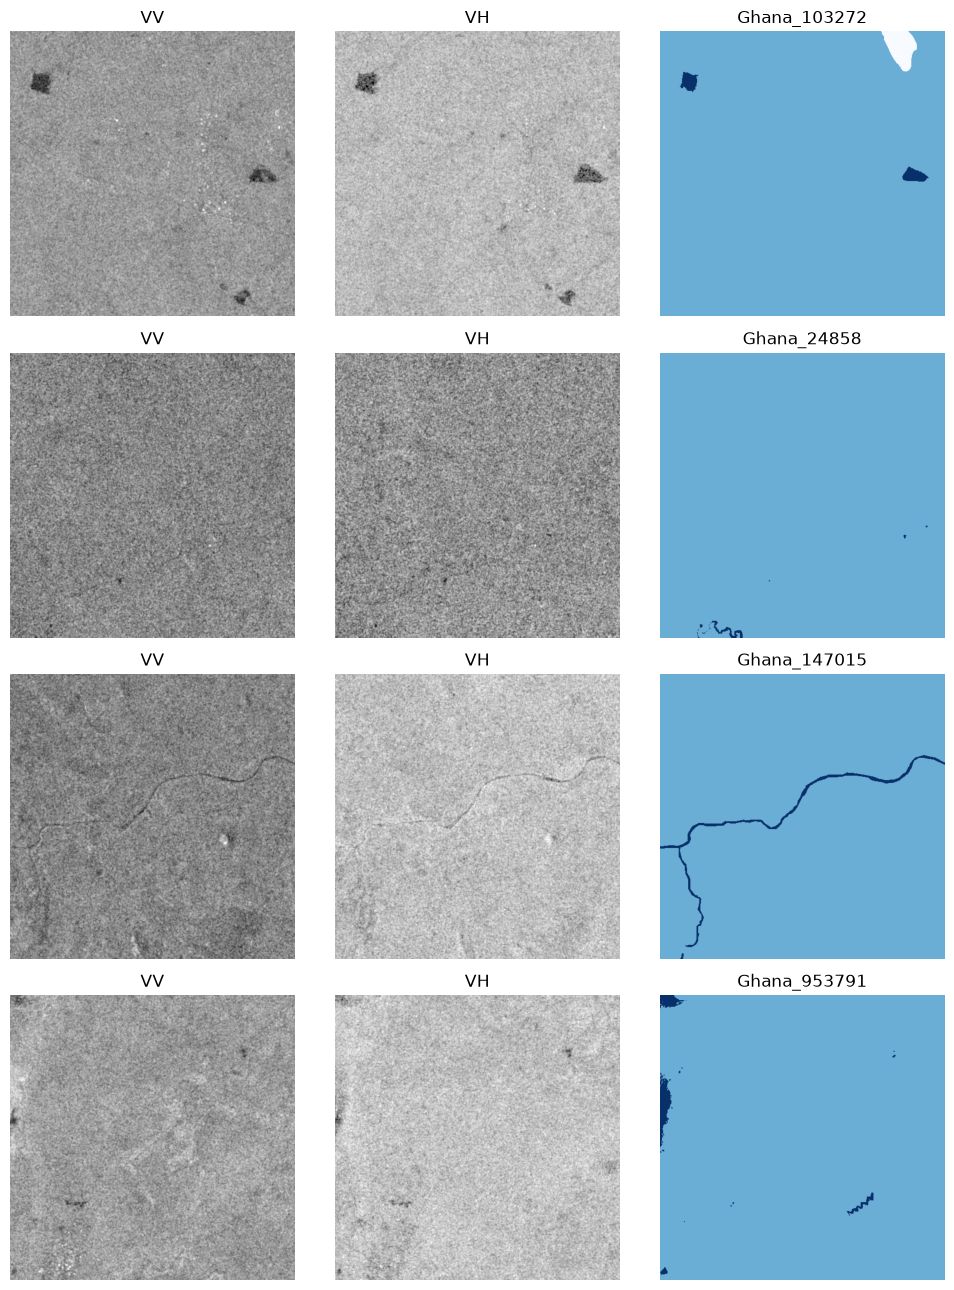

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 3, figsize=(10, 13))
for row, (s1_name, label_name) in enumerate(train[:4]):
    with rasterio.open(root / "S1Hand" / s1_name) as src:
        x = src.read().astype("float32")
    with rasterio.open(root / "LabelHand" / label_name) as src:
        y = src.read(1)
    axes[row, 0].imshow(np.clip(x[0], *VV_CLIP), cmap="gray")
    axes[row, 0].set_title("VV")
    axes[row, 1].imshow(np.clip(x[1], *VH_CLIP), cmap="gray")
    axes[row, 1].set_title("VH")
    axes[row, 2].imshow(y, cmap="Blues", vmin=-1, vmax=1)
    axes[row, 2].set_title(s1_name.split("_S1")[0])
    for a in axes[row]:
        a.axis("off")
plt.tight_layout()
figure_dir = PROJECT / "reports/figures"
figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_dir / "sen1floods11_training_examples.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
def update_counts(counts, pred, label):
    """Add one chip's pixels to running totals. Ignores label == -1."""
    valid = label != -1
    p = (pred == 1) & valid
    t = (label == 1) & valid
    counts["water_inter"] += (p & t).sum()
    counts["water_union"] += (p | t).sum()
    counts["dry_inter"] += (~p & ~t & valid).sum()
    counts["dry_union"] += ((~p | ~t) & valid).sum()

def summarise(counts):
    iou_water = counts["water_inter"] / counts["water_union"]
    iou_dry = counts["dry_inter"] / counts["dry_union"]
    return iou_water, (iou_water + iou_dry) / 2

print("Split files:", [f.name for f in (root / "splits").glob("*.csv")])

for split_name in ["flood_test_data.csv", "flood_bolivia_data.csv"]:
    split_path = root / "splits" / split_name
    if not split_path.exists():
        print("not found:", split_name)
        continue
    counts = dict(water_inter=0, water_union=0, dry_inter=0, dry_union=0)
    for s1_name, label_name in read_split(split_name):
        otsu_name = label_name.replace("LabelHand", "S1OtsuLabelHand")
        with rasterio.open(root / "LabelHand" / label_name) as src:
            label = src.read(1)
        with rasterio.open(root / "S1OtsuLabelHand" / otsu_name) as src:
            pred = src.read(1)
        update_counts(counts, pred, label)
    iou_water, miou = summarise(counts)
    print(f"{split_name}: Otsu water IoU {iou_water:.3f}  mIoU {miou:.3f}")

Split files: ['flood_bolivia_data.csv', 'flood_valid_data.csv', 'flood_test_data.csv', 'flood_train_data.csv']


flood_test_data.csv: Otsu water IoU 0.546  mIoU 0.731
flood_bolivia_data.csv: Otsu water IoU 0.697  mIoU 0.814


In [6]:
from floodrisk.datasets.sen1floods11 import Sen1Floods11
ds = Sen1Floods11(root, "train", augment=True)
x, y = ds[0]
print(len(ds), x.shape, x.dtype, y.shape, y.unique())
print("x mean/std:", x.mean().item(), x.std().item())

252 torch.Size([2, 512, 512]) torch.float32 torch.Size([512, 512]) tensor([-1,  0,  1])
x mean/std: 0.36264121532440186 0.5516207218170166
